In [27]:
from sklearn.datasets import load_iris
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score , confusion_matrix, classification_report


datf = load_iris(as_frame = True)
df = datf.frame
print(df.columns)
print(df.head())

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='object')
   sepal length (cm)  sepal width (cm)  ...  petal width (cm)  target
0                5.1               3.5  ...               0.2       0
1                4.9               3.0  ...               0.2       0
2                4.7               3.2  ...               0.2       0
3                4.6               3.1  ...               0.2       0
4                5.0               3.6  ...               0.2       0

[5 rows x 5 columns]


In [28]:
X = datf.data
y = datf.target
print(X.head())
print(y.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [29]:
X_train , X_test , y_train , y_test = train_test_split( X , y , test_size = 0.2 , random_state = 42)

In [30]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [31]:
kvals = [1,3,5,7,9]
accs = []

for k in kvals:
  model = KNeighborsClassifier(n_neighbors=k)
  model.fit(X_train, y_train)

  pred = model.predict(X_test)
  acc = accuracy_score(y_test, pred)
  accs.append(acc)
  print(f"K = {k} : Accuracy = {acc}")

K = 1 : Accuracy = 1.0
K = 3 : Accuracy = 1.0
K = 5 : Accuracy = 1.0
K = 7 : Accuracy = 1.0
K = 9 : Accuracy = 1.0


In [32]:
bestidn = accs.index(max(accs))
bestk = kvals[bestidn]
print(f"Best K = {bestk}")

Best K = 1


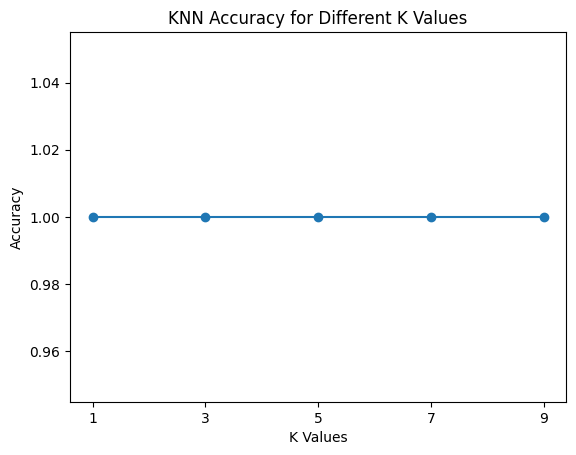

In [38]:
import matplotlib.pyplot as plt
plt.plot(kvals, accs, marker='o')
plt.xlabel("K Values")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different K Values")
plt.xticks(kvals)
#plt.grid(True)
plt.show()
